<a href="https://colab.research.google.com/github/Sourabh-IISER/LEAF_CLASSIFICATION/blob/main/notebooks/leaf_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATA LOADING AND IMAGE PROCESSING ~ Sourabh **

In [ ]:
!pip install -q opencv-python scikit-image scikit-learn pandas matplotlib seaborn pillow

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported.")

All libraries imported.


In [ ]:
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

OpenCV version: 5.0.0
NumPy version: 2.1.3
Pandas version: 2.2.3


In [21]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [22]:
import zipfile

zip_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total files in ZIP:", len(files))

print("\nFirst 50 files/folders:")
for item in files[:50]:
    print(item)

Total files in ZIP: 4502

First 50 files/folders:
Plants_2/images to predict/0001_0170.JPG
Plants_2/images to predict/0003_0179.JPG
Plants_2/images to predict/0005_0268.JPG
Plants_2/images to predict/0008_0148.JPG
Plants_2/images to predict/0015_0123.JPG
Plants_2/images to predict/0016_0118.JPG
Plants_2/images to predict/0019_0276.JPG
Plants_2/images to predict/0020_0271.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0006.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0007.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0008.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0009.JPG
Plants_2/test/Alstonia Scholaris diseased (P2a)/0014_0010.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0006.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0007.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0008.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0009.JPG
Plants_2/test/Alstonia Scholaris healthy (P2b)/0003_0010.JPG
Plants_

In [23]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    all_files = zip_ref.namelist()

# Find folders immediately inside Plants_2/test/
test_classes = set()

for file_path in all_files:
    parts = file_path.split("/")

    if len(parts) >= 3 and parts[0] == "Plants_2" and parts[1] == "test":
        test_classes.add(parts[2])

print("Classes found in test folder:")
for class_name in sorted(test_classes):
    print(class_name)

print("\nNumber of classes:", len(test_classes))

Classes found in test folder:
Alstonia Scholaris diseased (P2a)
Alstonia Scholaris healthy (P2b)
Arjun diseased (P1a)
Arjun healthy (P1b)
Bael diseased (P4b)
Basil healthy (P8)
Chinar diseased (P11b)
Chinar healthy (P11a)
Gauva diseased (P3b)
Gauva healthy (P3a)
Jamun diseased (P5b)
Jamun healthy (P5a)
Jatropha diseased (P6b)
Jatropha healthy (P6a)
Lemon diseased (P10b)
Lemon healthy (P10a)
Mango diseased (P0b)
Mango healthy (P0a)
Pomegranate diseased (P9b)
Pomegranate healthy (P9a)
Pongamia Pinnata diseased (P7b)
Pongamia Pinnata healthy (P7a)

Number of classes: 22


In [ ]:
train_classes = set()

for file_path in all_files:
    parts = file_path.split("/")

    if len(parts) >= 3 and parts[0] == "Plants_2" and parts[1] == "train":
        train_classes.add(parts[2])

print("Classes found in train folder:")
for class_name in sorted(train_classes):
    print(class_name)

print("\nNumber of classes:", len(train_classes))

Classes found in train folder:
Alstonia Scholaris diseased (P2a)
Alstonia Scholaris healthy (P2b)
Arjun diseased (P1a)
Arjun healthy (P1b)
Bael diseased (P4b)
Basil healthy (P8)
Chinar diseased (P11b)
Chinar healthy (P11a)
Gauva diseased (P3b)
Gauva healthy (P3a)
Jamun diseased (P5b)
Jamun healthy (P5a)
Jatropha diseased (P6b)
Jatropha healthy (P6a)
Lemon diseased (P10b)
Lemon healthy (P10a)
Mango diseased (P0b)
Mango healthy (P0a)
Pomegranate diseased (P9b)
Pomegranate healthy (P9a)
Pongamia Pinnata diseased (P7b)
Pongamia Pinnata healthy (P7a)

Number of classes: 22


In [ ]:
import os

project_dataset_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/images"

species = [
    "Mango",
    "Gauva",
    "Jamun",
    "Lemon",
    "Pomegranate"
]

for species_name in species:
    os.makedirs(
        os.path.join(project_dataset_path, species_name),
        exist_ok=True
    )

print("Project dataset folders created.")

for species_name in species:
    print(species_name)

Project dataset folders created.
Mango
Gauva
Jamun
Lemon
Pomegranate


In [ ]:
import zipfile
import os
import shutil

zip_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/archive.zip"

# Final class name : original Kaggle folder names
class_mapping = {
    "Mango": [
        "Mango healthy (P0a)",
        "Mango diseased (P0b)"
    ],
    "Guava": [
        "Gauva healthy (P3a)",
        "Gauva diseased (P3b)"
    ],
    "Jamun": [
        "Jamun healthy (P5a)",
        "Jamun diseased (P5b)"
    ],
    "Lemon": [
        "Lemon healthy (P10a)",
        "Lemon diseased (P10b)"
    ],
    "Pomegranate": [
        "Pomegranate healthy (P9a)",
        "Pomegranate diseased (P9b)"
    ]
}

# Create separate train and test folders
for split in ["train", "test"]:
    for class_name in class_mapping:
        folder_path = os.path.join(
            project_dataset_path,
            split,
            class_name
        )
        os.makedirs(folder_path, exist_ok=True)

# Extract images
with zipfile.ZipFile(zip_path, "r") as zip_ref:

    all_files = zip_ref.namelist()

    for split in ["train", "test"]:

        for final_class, original_classes in class_mapping.items():

            output_folder = os.path.join(
                project_dataset_path,
                split,
                final_class
            )

            for original_class in original_classes:

                prefix = f"Plants_2/{split}/{original_class}/"

                for file_path in all_files:

                    if (
                        file_path.startswith(prefix)
                        and file_path.lower().endswith(
                            (".jpg", ".jpeg", ".png", ".bmp")
                        )
                    ):

                        file_name = os.path.basename(file_path)

                        # Prevent duplicate filenames
                        new_file_name = (
                            f"{original_class.replace(' ', '_')}_{file_name}"
                        )

                        output_path = os.path.join(
                            output_folder,
                            new_file_name
                        )

                        with zip_ref.open(file_path) as source:
                            with open(output_path, "wb") as target:
                                shutil.copyfileobj(source, target)

print("Extraction completed successfully!")

KeyboardInterrupt: 

In [ ]:
for split in ["train", "test"]:

    print(f"\n_________ {split.upper()} _________")

    for class_name in ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]:

        folder = os.path.join(
            project_dataset_path,
            split,
            class_name
        )

        image_files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]

        print(f"{class_name}: {len(image_files)} images")


_________ TRAIN _________
Mango: 414 images
Guava: 398 images
Jamun: 603 images
Lemon: 216 images
Pomegranate: 538 images

_________ TEST _________
Mango: 10 images
Guava: 10 images
Jamun: 10 images
Lemon: 10 images
Pomegranate: 10 images


In [ ]:
import cv2
import os
import numpy as np

image_sizes = []

for split in ["train", "test"]:
    for class_name in ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]:

        folder = os.path.join(
            project_dataset_path,
            split,
            class_name
        )

        for file_name in os.listdir(folder):

            if file_name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):

                image_path = os.path.join(folder, file_name)

                image = cv2.imread(image_path)

                if image is not None:
                    height, width = image.shape[:2]
                    image_sizes.append((width, height))

print("Total images checked:", len(image_sizes))

widths = [size[0] for size in image_sizes]
heights = [size[1] for size in image_sizes]

print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

print("\nMost common image size:")

from collections import Counter

size_counts = Counter(image_sizes)

for size, count in size_counts.most_common(10):
    print(size, ":", count, "images")

Total images checked: 2219
Minimum width: 6000
Maximum width: 6000
Minimum height: 4000
Maximum height: 4000

Most common image size:
(6000, 4000) : 2219 images


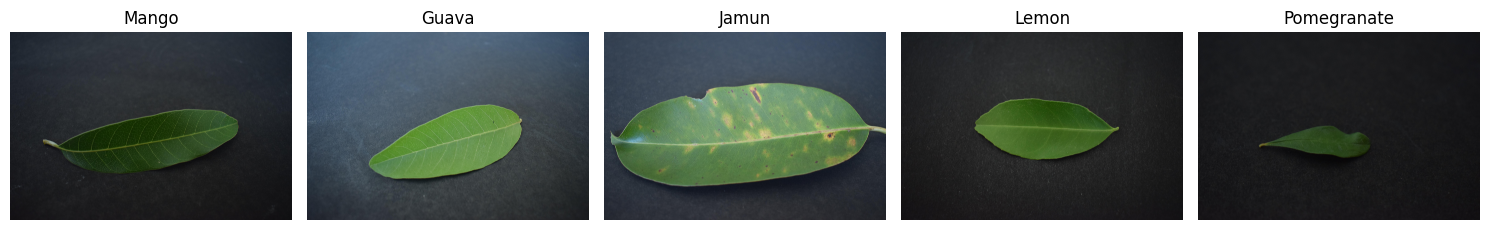

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os
import random

classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

plt.figure(figsize=(15, 10))

plot_number = 1

for class_name in classes:

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected_image = random.choice(image_files)

    image_path = os.path.join(folder, selected_image)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, plot_number)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

    plot_number += 1

plt.tight_layout()
plt.show()

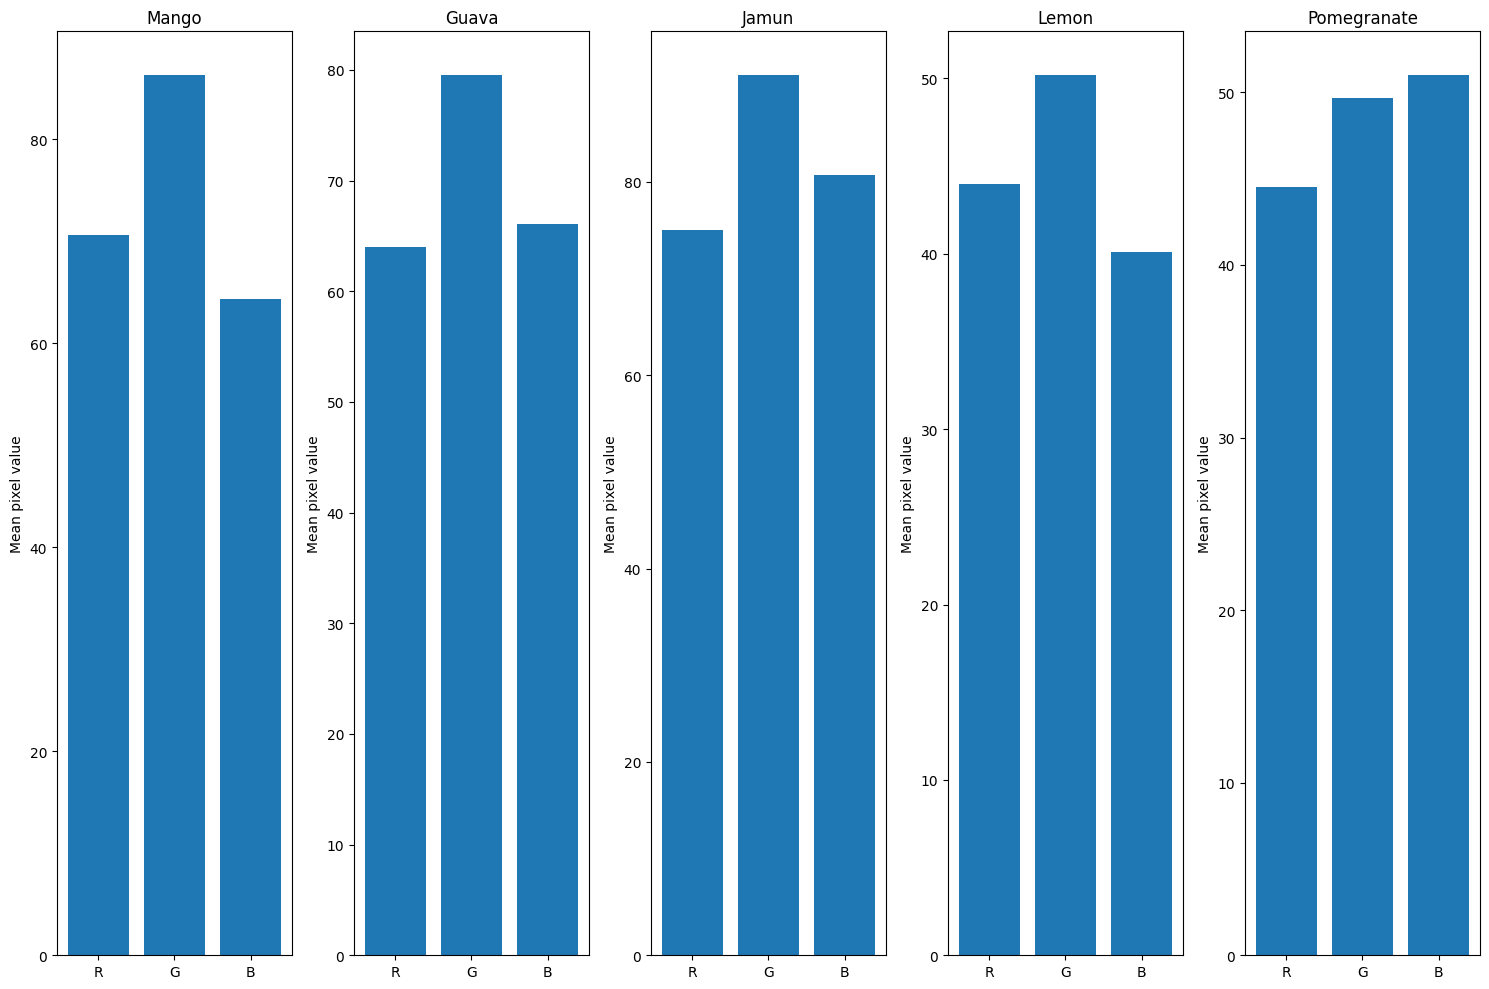

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os
import random
import numpy as np

classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

plt.figure(figsize=(15, 10))

plot_number = 1

for class_name in classes:

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    selected_image = random.choice(image_files)

    image_path = os.path.join(folder, selected_image)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Calculate average RGB values
    mean_rgb = np.mean(image, axis=(0, 1))

    plt.subplot(1, 5, plot_number)
    plt.bar(["R", "G", "B"], mean_rgb)
    plt.title(class_name)
    plt.ylabel("Mean pixel value")

    plot_number += 1

plt.tight_layout()
plt.show()

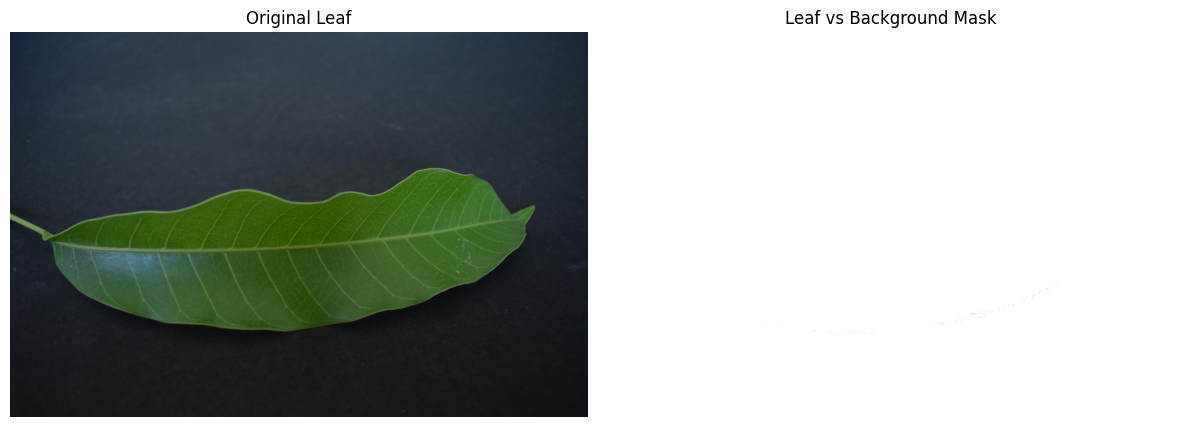

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

# Select one Mango training image
mango_folder = os.path.join(
    project_dataset_path,
    "train",
    "Mango"
)

image_file = os.listdir(mango_folder)[0]
image_path = os.path.join(mango_folder, image_file)

# Read image
image = cv2.imread(image_path)

# Convert BGR to RGB for displaying
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Create a simple mask:
# black background = 0
# leaf = 1
_, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Leaf")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Leaf vs Background Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Check the grayscale pixel-value distribution

print("Minimum grayscale value:", gray.min())
print("Maximum grayscale value:", gray.max())
print("Mean grayscale value:", gray.mean())

# Show some important percentiles
print("\nGrayscale percentiles:")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print(f"{p}%:", np.percentile(gray, p))

Minimum grayscale value: 7
Maximum grayscale value: 173
Mean grayscale value: 50.064198041666664

Grayscale percentiles:
1%: 16.0
5%: 21.0
10%: 24.0
25%: 28.0
50%: 51.0
75%: 64.0
90%: 80.0
95%: 87.0
99%: 108.0


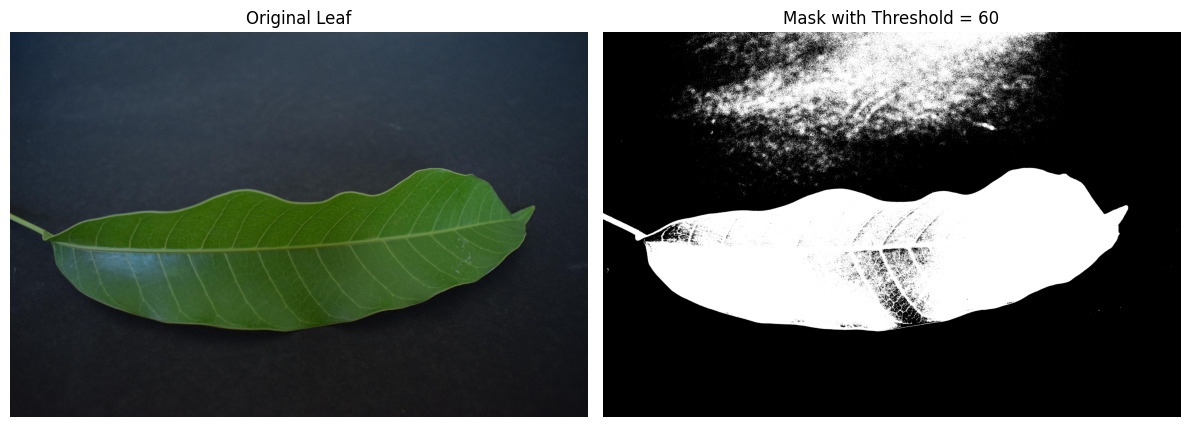

In [ ]:
# Try a higher threshold to separate the leaf from the dark background

threshold_value = 60

_, mask_20 = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Leaf")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_20, cmap="gray")
plt.title("Mask with Threshold = 60")
plt.axis("off")

plt.tight_layout()
plt.show()

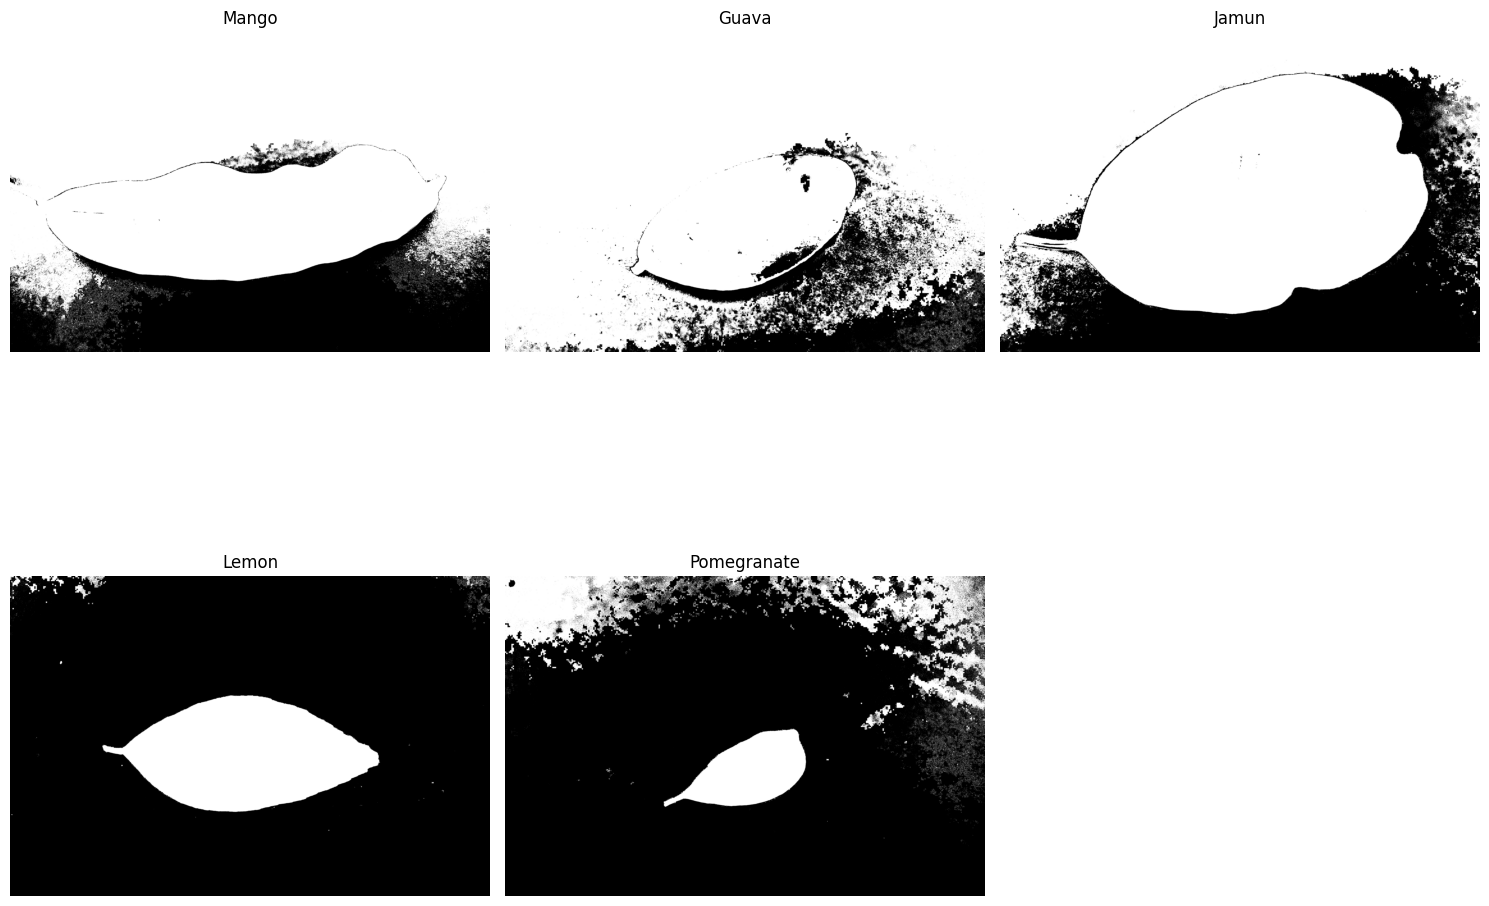

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

plt.figure(figsize=(15, 12))

for i, class_name in enumerate(classes):

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    # Take the first image from this class
    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    image_path = os.path.join(folder, image_files[0])

    # Read image
    image = cv2.imread(image_path)

    # Convert BGR → RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert RGB → HSV
    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)

    # Extract HSV channels
    H = hsv[:, :, 0]
    S = hsv[:, :, 1]
    V = hsv[:, :, 2]

    # Create a mask using saturation and brightness
    mask = ((S > 40) & (V > 30)).astype("uint8") * 255

    # Display the mask
    plt.subplot(2, 3, i + 1)
    plt.imshow(mask, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

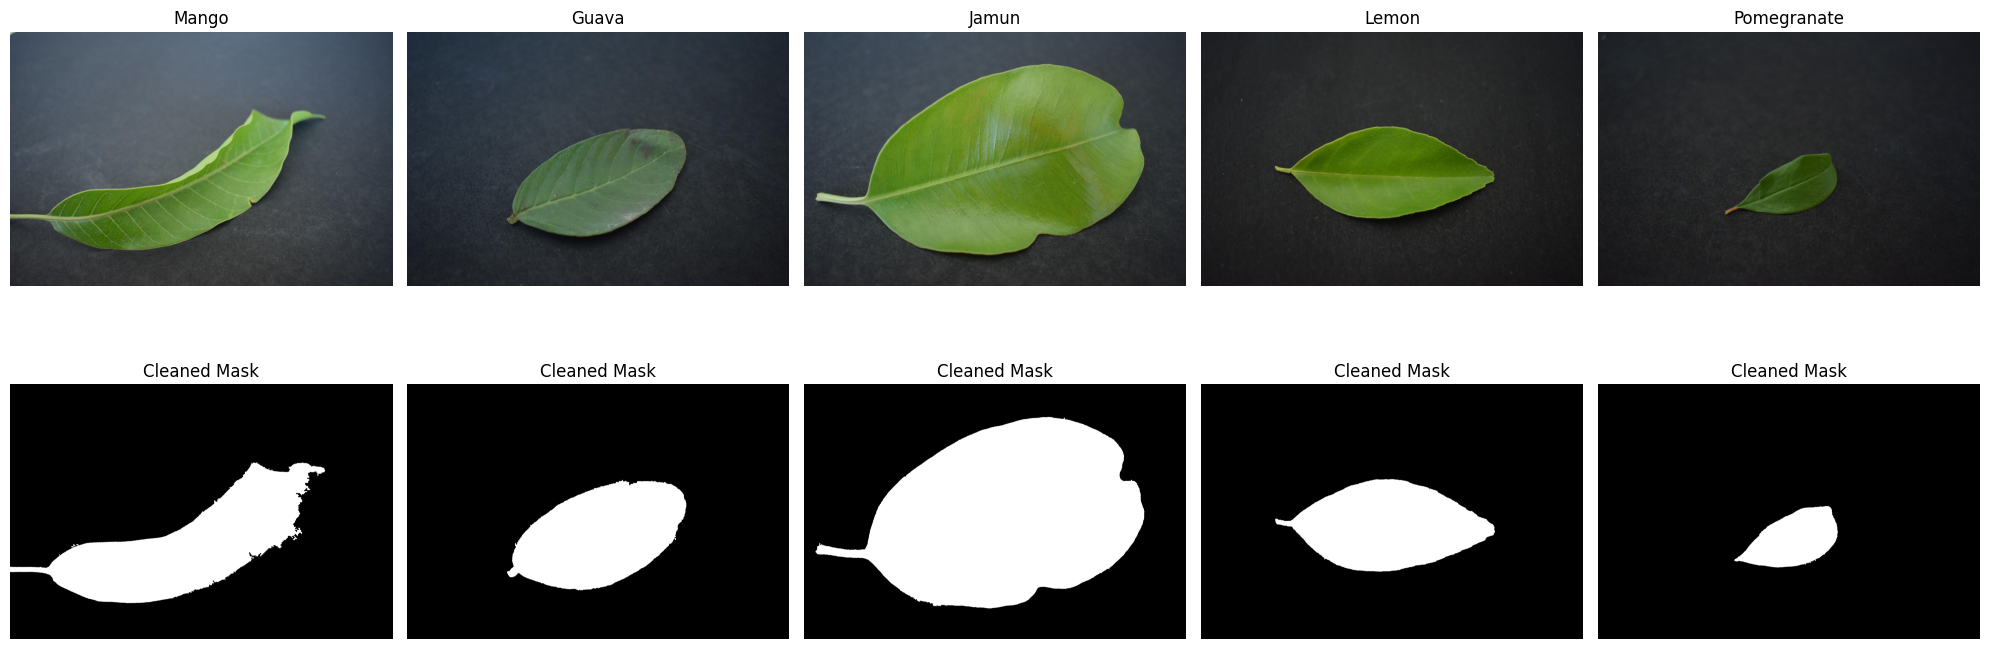

In [41]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

def create_leaf_mask(image):

    # Convert image from BGR to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # HSV ranges for green leaf detection
    lower_green = np.array([25, 30, 20])
    upper_green = np.array([100, 255, 255])

    # Create initial mask
    mask = cv2.inRange(hsv, lower_green, upper_green)

    # Remove small noise
    kernel = np.ones((7, 7), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    # Fill small gaps inside the leaf
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Find contours
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Keep the largest detected object
    if contours:

        largest_contour = max(
            contours,
            key=cv2.contourArea
        )

        clean_mask = np.zeros_like(mask)

        cv2.drawContours(
            clean_mask,
            [largest_contour],
            -1,
            255,
            thickness=cv2.FILLED
        )

        return clean_mask

    return mask


# Select one image from each class
classes = [
    "Mango",
    "Guava",
    "Jamun",
    "Lemon",
    "Pomegranate"
]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i, class_name in enumerate(classes):

    folder = os.path.join(
        project_dataset_path,
        "train",
        class_name
    )

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        )
    ]

    image_path = os.path.join(
        folder,
        image_files[0]
    )

    image = cv2.imread(image_path)

    # Create cleaned mask
    mask = create_leaf_mask(image)

    # Display original image
    axes[0, i].imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    axes[0, i].set_title(class_name)
    axes[0, i].axis("off")

    # Display cleaned mask
    axes[1, i].imshow(
        mask,
        cmap="gray"
    )
    axes[1, i].set_title("Cleaned Mask")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# **FEATURE EXTRACTION**  ~ DISHANT

In [17]:
import cv2
import numpy as np

def extract_color_features(image, mask):
    """
    Extract color features from the leaf region.

    Parameters:
        image: Original image in BGR format.
        mask: Binary leaf mask where the leaf is white (255)
              and the background is black (0).

    Returns:
        A dictionary containing RGB and HSV color features.
    """

    # Select only the pixels belonging to the leaf
    leaf_pixels_bgr = image[mask > 0]

    # Convert the image from BGR to RGB
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    leaf_pixels_rgb = image_rgb[mask > 0]

    # Convert the image from BGR to HSV
    image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    leaf_pixels_hsv = image_hsv[mask > 0]

    # Calculate RGB statistics
    r_mean, g_mean, b_mean = np.mean(leaf_pixels_rgb, axis=0)
    r_std, g_std, b_std = np.std(leaf_pixels_rgb, axis=0)

    # Calculate HSV statistics
    h_mean, s_mean, v_mean = np.mean(leaf_pixels_hsv, axis=0)
    h_std, s_std, v_std = np.std(leaf_pixels_hsv, axis=0)

    # Store the features
    features = {
        "R_mean": r_mean,
        "G_mean": g_mean,
        "B_mean": b_mean,
        "R_std": r_std,
        "G_std": g_std,
        "B_std": b_std,
        "H_mean": h_mean,
        "S_mean": s_mean,
        "V_mean": v_mean,
        "H_std": h_std,
        "S_std": s_std,
        "V_std": v_std
    }

    return features

In [42]:

import cv2
import os
import pandas as pd

train_path = os.path.join(project_dataset_path, "train")
classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

test_results = []

for class_name in classes:
    class_folder = os.path.join(train_path, class_name)
    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    image_path = os.path.join(class_folder, image_files[0])
    image = cv2.imread(image_path)

    if image is None:
        print("Could not read:", image_path)
        continue

    # Resize before masking and feature extraction
    image = cv2.resize(image, (256, 256))

    mask = create_leaf_mask(image)

    if cv2.countNonZero(mask) == 0:
        print("Empty mask:", class_name)
        continue

    features = extract_color_features(image, mask)
    features["Species"] = class_name
    test_results.append(features)

test_df = pd.DataFrame(test_results)

print("Images successfully processed:", len(test_df))
display(test_df.round(2))


Images successfully processed: 5


,R_mean,G_mean,B_mean,R_std,G_std,B_std,H_mean,S_mean,V_mean,H_std,S_std,V_std,Species
0,100.51,142.06,73.66,20.77,16.62,20.76,49.96,123.46,142.14,8.90,31.78,16.36,Mango
1,153.03,150.31,76.76,23.48,18.86,22.56,29.06,131.19,154.94,3.28,24.88,21.50,Guava
2,114.23,162.48,80.93,14.00,18.02,21.19,48.29,130.04,162.50,6.01,20.34,17.93,Jamun
3,104.98,138.36,44.98,24.57,23.79,23.44,40.77,176.40,138.40,2.21,35.71,23.76,Lemon
4,63.08,97.39,60.79,11.20,16.57,12.97,60.75,101.24,97.87,13.64,22.66,15.52,Pomegranate


In [25]:
import os

project_dataset_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/images"

print("Dataset path:", project_dataset_path)
print("Path exists:", os.path.exists(project_dataset_path))

print("Folders found:")
print(os.listdir(project_dataset_path))

Dataset path: /content/drive/MyDrive/Leaf_Classification/Dataset/images
Path exists: True
Folders found:
['Mango', 'Gauva', 'Jamun', 'Lemon', 'Pomegranate', 'train', 'test']


In [26]:

import cv2
import os
import pandas as pd

train_path = os.path.join(project_dataset_path, "train")
classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

test_results = []

for class_name in classes:
    class_folder = os.path.join(train_path, class_name)
    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    image_path = os.path.join(class_folder, image_files[0])
    image = cv2.imread(image_path)

    if image is None:
        print("Could not read:", image_path)
        continue

    # Resize before masking and feature extraction
    image = cv2.resize(image, (256, 256))

    mask = create_leaf_mask(image)

    if cv2.countNonZero(mask) == 0:
        print("Empty mask:", class_name)
        continue

    features = extract_color_features(image, mask)
    features["Species"] = class_name
    test_results.append(features)

test_df = pd.DataFrame(test_results)

print("Images successfully processed:", len(test_df))
display(test_df.round(2))


NameError: name 'create_leaf_mask' is not defined

In [27]:

import os
import cv2
import pandas as pd

train_path = os.path.join(project_dataset_path, "train")
classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

all_features = []
failed_images = 0

for class_name in classes:
    class_folder = os.path.join(train_path, class_name)

    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    class_count = 0

    for filename in image_files:
        image_path = os.path.join(class_folder, filename)
        image = cv2.imread(image_path)

        if image is None:
            failed_images += 1
            continue

        # Resize before masking to reduce processing time
        image = cv2.resize(image, (256, 256))
        mask = create_leaf_mask(image)

        if cv2.countNonZero(mask) == 0:
            failed_images += 1
            continue

        features = extract_color_features(image, mask)
        features["Species"] = class_name
        all_features.append(features)
        class_count += 1

    print(f"{class_name}: processed {class_count}/{len(image_files)} images")

color_features_df = pd.DataFrame(all_features)

print("\nFeature extraction completed.")
print("Total valid images:", len(color_features_df))
print("Failed or empty-mask images:", failed_images)
print("\nImages processed per species:")
print(color_features_df["Species"].value_counts())

display(color_features_df.head().round(2))


NameError: name 'create_leaf_mask' is not defined

In [ ]:

#didn't run due to large size was taking very long
import os
import cv2
import pandas as pd

train_path = os.path.join(project_dataset_path, "train")
classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

all_features = []
failed_images = 0

for class_name in classes:
    class_folder = os.path.join(train_path, class_name)

    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    print(f"Processing {class_name}: {len(image_files)} images")

    for filename in image_files:
        image_path = os.path.join(class_folder, filename)
        image = cv2.imread(image_path)

        if image is None:
            failed_images += 1
            continue

        mask = create_leaf_mask(image)

        # Skip images where the mask detects no leaf pixels
        if cv2.countNonZero(mask) == 0:
            failed_images += 1
            continue

        features = extract_color_features(image, mask)
        features["Species"] = class_name
        all_features.append(features)

color_features_df = pd.DataFrame(all_features)

print("\nFeature extraction completed.")
print("Total valid images:", len(color_features_df))
print("Failed or empty-mask images:", failed_images)
print("\nImages processed per species:")
print(color_features_df["Species"].value_counts())

display(color_features_df.head().round(2))


Processing Mango: 414 images


KeyboardInterrupt: 

In [ ]:

for species in ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]:
    print(f"\n{species}:")
    display(
        color_features_df[
            color_features_df["Species"] == species
        ].head(5).round(2)
    )



Mango:


,R_mean,G_mean,B_mean,R_std,G_std,B_std,H_mean,S_mean,V_mean,H_std,S_std,V_std,Species
0,100.51,142.06,73.66,20.77,16.62,20.76,49.96,123.46,142.14,8.90,31.78,16.36,Mango
1,94.78,138.98,65.44,21.07,16.55,28.94,48.91,138.92,139.01,6.22,43.07,16.47,Mango
2,76.90,114.76,63.69,23.18,18.87,26.12,53.83,120.90,114.86,9.08,40.00,18.80,Mango
3,96.38,128.78,88.63,18.30,15.52,14.60,55.06,81.64,128.83,7.98,15.93,15.47,Mango
4,101.07,129.70,88.72,18.39,15.52,10.48,52.44,80.71,129.79,9.78,17.79,15.45,Mango



Guava:


,R_mean,G_mean,B_mean,R_std,G_std,B_std,H_mean,S_mean,V_mean,H_std,S_std,V_std,Species
412,153.03,150.31,76.76,23.48,18.86,22.56,29.06,131.19,154.94,3.28,24.88,21.50,Guava
413,173.00,168.32,91.19,16.51,13.90,13.52,28.42,121.80,174.00,2.29,14.42,15.46,Guava
414,119.89,140.03,87.77,10.40,14.27,11.30,41.27,95.81,140.43,7.37,13.03,13.56,Guava
415,106.65,137.74,78.18,25.17,30.34,26.61,45.72,113.11,137.89,6.19,30.18,30.00,Guava
416,127.27,145.43,89.51,10.80,13.09,13.61,39.45,99.22,145.88,5.88,14.36,12.34,Guava



Jamun:


,R_mean,G_mean,B_mean,R_std,G_std,B_std,H_mean,S_mean,V_mean,H_std,S_std,V_std,Species
809,114.23,162.48,80.93,14.00,18.02,21.19,48.29,130.04,162.50,6.01,20.34,17.93,Jamun
810,123.91,180.43,116.79,17.67,22.97,46.80,58.94,110.01,180.83,15.19,26.34,23.55,Jamun
811,98.48,152.05,104.68,18.74,21.31,36.15,63.88,104.83,152.28,14.02,22.84,21.27,Jamun
812,103.16,148.29,103.13,17.86,18.77,30.85,61.31,96.13,148.35,12.74,21.54,18.71,Jamun
813,138.36,188.85,103.11,32.22,44.94,30.58,51.89,117.00,189.20,14.56,28.10,44.15,Jamun



Lemon:


,R_mean,G_mean,B_mean,R_std,G_std,B_std,H_mean,S_mean,V_mean,H_std,S_std,V_std,Species
1404,104.98,138.36,44.98,24.57,23.79,23.44,40.77,176.40,138.40,2.21,35.71,23.76,Lemon
1405,96.96,124.32,38.90,19.64,21.86,21.35,39.58,179.85,124.37,2.63,33.80,21.81,Lemon
1406,97.15,126.57,36.64,23.21,24.43,25.24,39.88,187.65,126.62,2.79,42.64,24.35,Lemon
1407,103.57,122.58,50.55,26.11,24.81,24.72,37.21,156.12,124.06,6.00,38.56,24.63,Lemon
1408,105.45,135.79,50.01,16.84,17.76,21.68,40.60,164.04,135.83,2.53,34.93,17.64,Lemon



Pomegranate:


,R_mean,G_mean,B_mean,R_std,G_std,B_std,H_mean,S_mean,V_mean,H_std,S_std,V_std,Species
1620,63.08,97.39,60.79,11.20,16.57,12.97,60.75,101.24,97.87,13.64,22.66,15.52,Pomegranate
1621,52.57,81.80,37.23,11.86,14.51,15.05,50.63,142.34,81.83,7.44,34.84,14.47,Pomegranate
1622,58.59,92.80,45.22,13.78,19.07,23.33,53.37,139.78,92.94,12.98,43.95,18.83,Pomegranate
1623,65.51,99.29,48.54,12.02,16.70,10.13,50.75,130.50,99.32,6.85,20.20,16.61,Pomegranate
1624,59.59,91.66,50.02,9.17,12.57,11.62,54.20,118.02,91.70,8.11,21.74,12.45,Pomegranate


In [ ]:

import os

features_path = os.path.join(
    "/content/drive/MyDrive/Leaf_Classification",
    "color_features.csv"
)

color_features_df.to_csv(features_path, index=False)

print("Color features saved successfully.")
print("File location:", features_path)
print("Rows:", len(color_features_df))
print("Columns:", len(color_features_df.columns))


Color features saved successfully.
File location: /content/drive/MyDrive/Leaf_Classification/color_features.csv
Rows: 2158
Columns: 13


**Random Forest** ~Jayant

In [29]:
%pip install scikit-image

In [12]:

import cv2
import numpy as np
import pandas as pd

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

try:
    from skimage.feature import local_binary_pattern
    print("scikit-image: Ready")
except ImportError:
    print("scikit-image: Not installed")


OpenCV: 5.0.0
NumPy: 2.1.3
Pandas: 2.2.3
scikit-image: Ready


In [9]:

import cv2
import numpy as np
from skimage.feature import local_binary_pattern

def extract_texture_features(image, mask):
    # Convert the image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Keep the detected leaf region
    gray_leaf = gray.copy()
    gray_leaf[mask == 0] = 0

    # Calculate Local Binary Pattern (LBP)
    radius = 2
    n_points = 8 * radius
    lbp = local_binary_pattern(
        gray_leaf, n_points, radius, method="uniform"
    )

    # Use only pixels inside the leaf mask
    leaf_lbp = lbp[mask > 0]

    # Create a normalized histogram of texture patterns
    n_bins = n_points + 2
    hist, _ = np.histogram(
        leaf_lbp,
        bins=np.arange(0, n_bins + 1),
        range=(0, n_bins)
    )

    hist = hist.astype(float)
    hist = hist / (hist.sum() + 1e-7)

    return {
        f"LBP_{i}": hist[i]
        for i in range(len(hist))
    }


def extract_shape_features(mask):
    # Find the outer boundaries of the detected leaf
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return {
            "Leaf_Area": 0,
            "Leaf_Perimeter": 0,
            "Aspect_Ratio": 0,
            "Extent": 0
        }

    # Select the largest detected contour
    contour = max(contours, key=cv2.contourArea)

    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    x, y, width, height = cv2.boundingRect(contour)

    aspect_ratio = width / height if height > 0 else 0
    bounding_box_area = width * height
    extent = area / bounding_box_area if bounding_box_area > 0 else 0

    return {
        "Leaf_Area": area,
        "Leaf_Perimeter": perimeter,
        "Aspect_Ratio": aspect_ratio,
        "Extent": extent
    }

print("Texture and shape feature functions are ready.")


Texture and shape feature functions are ready.


In [28]:

import os
import cv2
import pandas as pd

train_path = os.path.join(project_dataset_path, "train")
classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

test_features = []

for species in classes:
    class_folder = os.path.join(train_path, species)

    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    image_path = os.path.join(class_folder, image_files[0])
    image = cv2.imread(image_path)

    if image is None:
        print("Could not read image:", image_path)
        continue

    # Resize for faster processing
    image = cv2.resize(image, (256, 256))

    # Create the leaf mask
    mask = create_leaf_mask(image)

    if cv2.countNonZero(mask) == 0:
        print("Empty mask for:", species)
        continue

    # Extract texture and shape features
    features = extract_texture_features(image, mask)
    features.update(extract_shape_features(mask))
    features["Species"] = species

    test_features.append(features)

test_features_df = pd.DataFrame(test_features)

print("Images successfully processed:", len(test_features_df))
print("Number of texture and shape features:",
      len(test_features_df.columns) - 1)

display(test_features_df.round(3))


NameError: name 'create_leaf_mask' is not defined

In [29]:

import os
import cv2
import pandas as pd

train_path = os.path.join(project_dataset_path, "train")
classes = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

all_texture_shape_features = []
failed_images = 0

for species in classes:
    class_folder = os.path.join(train_path, species)

    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    class_count = 0

    for filename in image_files:
        image_path = os.path.join(class_folder, filename)
        image = cv2.imread(image_path)

        if image is None:
            failed_images += 1
            continue

        image = cv2.resize(image, (256, 256))
        mask = create_leaf_mask(image)

        if cv2.countNonZero(mask) == 0:
            failed_images += 1
            continue

        features = extract_texture_features(image, mask)
        features.update(extract_shape_features(mask))

        features["Filename"] = filename
        features["Species"] = species

        all_texture_shape_features.append(features)
        class_count += 1

    print(f"{species}: processed {class_count}/{len(image_files)} images")

texture_shape_df = pd.DataFrame(all_texture_shape_features)

print("\nFeature extraction completed.")
print("Total valid images:", len(texture_shape_df))
print("Failed or empty-mask images:", failed_images)
print("Total columns:", len(texture_shape_df.columns))
print("\nImages processed per species:")
print(texture_shape_df["Species"].value_counts())

display(texture_shape_df.head().round(3))


NameError: name 'create_leaf_mask' is not defined

In [30]:

import os

texture_shape_path = os.path.join(
    "/content/drive/MyDrive/Leaf_Classification",
    "texture_shape_features.csv"
)

texture_shape_df.to_csv(texture_shape_path, index=False)

print("Texture and shape features saved successfully.")
print("File location:", texture_shape_path)
print("Rows:", len(texture_shape_df))
print("Columns:", len(texture_shape_df.columns))
print("\nSaved feature groups:")
print("- 18 LBP texture features")
print("- 4 shape features")
print("- Filename")
print("- Species label")


NameError: name 'texture_shape_df' is not defined

In [31]:

# Step 6: Combine color, texture, and shape features

# Create an image order number within each species
color_features_df["Image_Order"] = (
    color_features_df.groupby("Species").cumcount()
)

texture_shape_df["Image_Order"] = (
    texture_shape_df.groupby("Species").cumcount()
)

# Combine the two tables using species and image order
combined_features_df = pd.merge(
    color_features_df,
    texture_shape_df,
    on=["Species", "Image_Order"],
    how="inner",
    validate="one_to_one"
)

# Remove the temporary order column
combined_features_df = combined_features_df.drop(
    columns=["Image_Order"]
)

# Check the combined dataset
print("Combined dataset shape:", combined_features_df.shape)
print("\nImages per species:")
print(combined_features_df["Species"].value_counts())

print("\nTotal columns:", len(combined_features_df.columns))
print("Filename column present:", "Filename" in combined_features_df.columns)
print("\nFirst five rows:")
display(combined_features_df.head())


NameError: name 'color_features_df' is not defined

In [32]:
import os
import pandas as pd
import numpy as np

folder = "/content/drive/MyDrive/Leaf_Classification"

# Load the two saved feature files
color_df = pd.read_csv(
    os.path.join(folder, "color_features.csv")
)

texture_shape_df = pd.read_csv(
    os.path.join(folder, "texture_shape_features.csv")
)

# Check that the species counts match
print("Color features:", color_df.shape)
print("Texture and shape features:", texture_shape_df.shape)

print("\nColor counts:")
print(color_df["Species"].value_counts().sort_index())

print("\nTexture and shape counts:")
print(texture_shape_df["Species"].value_counts().sort_index())

# Add a row number within each species to match corresponding rows
color_df["row_order"] = color_df.groupby("Species").cumcount()
texture_shape_df["row_order"] = texture_shape_df.groupby("Species").cumcount()

# Combine the features
combined_df = pd.merge(
    color_df,
    texture_shape_df,
    on=["Species", "row_order"],
    how="inner",
    validate="one_to_one"
)

# Remove the temporary matching column
combined_df.drop(columns=["row_order"], inplace=True)

# Save the combined dataset
combined_path = os.path.join(folder, "combined_features.csv")
combined_df.to_csv(combined_path, index=False)

print("\nCombined dataset recreated and saved!")
print("Shape:", combined_df.shape)
print("Saved to:", combined_path)
print("Images per species:")
print(combined_df["Species"].value_counts())

Color features: (2158, 13)
Texture and shape features: (2158, 24)

Color counts:
Species
Guava          397
Jamun          595
Lemon          216
Mango          412
Pomegranate    538
Name: count, dtype: int64

Texture and shape counts:
Species
Guava          397
Jamun          595
Lemon          216
Mango          412
Pomegranate    538
Name: count, dtype: int64

Combined dataset recreated and saved!
Shape: (2158, 36)
Saved to: /content/drive/MyDrive/Leaf_Classification/combined_features.csv
Images per species:
Species
Jamun          595
Pomegranate    538
Mango          412
Guava          397
Lemon          216
Name: count, dtype: int64


In [33]:
# Check missing values
print("Total missing values:", combined_df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", combined_df.duplicated().sum())

# Select numerical feature columns only
feature_columns = combined_df.select_dtypes(
    include=np.number
).columns

# Check infinite values
print(
    "Infinite values:",
    np.isinf(combined_df[feature_columns].to_numpy()).sum()
)

# Check the dataset dimensions
print("\nDataset shape:", combined_df.shape)

# Confirm the class distribution
print("\nImages per species:")
print(combined_df["Species"].value_counts())

Total missing values: 0
Duplicate rows: 0
Infinite values: 0

Dataset shape: (2158, 36)

Images per species:
Species
Jamun          595
Pomegranate    538
Mango          412
Guava          397
Lemon          216
Name: count, dtype: int64


In [34]:
from sklearn.model_selection import train_test_split

# Separate input features and target labels
X = combined_df.drop(columns=["Species", "Filename"])
y = combined_df["Species"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the results
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining images per species:")
print(y_train.value_counts().sort_index())

print("\nValidation images per species:")
print(y_val.value_counts().sort_index())

Training features: (1726, 34)
Validation features: (432, 34)

Training images per species:
Species
Guava          318
Jamun          476
Lemon          173
Mango          329
Pomegranate    430
Name: count, dtype: int64

Validation images per species:
Species
Guava           79
Jamun          119
Lemon           43
Mango           83
Pomegranate    108
Name: count, dtype: int64


In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict species in the validation set
y_val_pred = rf_model.predict(X_val)

# Calculate validation accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Random Forest training completed!")
print("Number of trees:", rf_model.n_estimators)
print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

Random Forest training completed!
Number of trees: 200
Validation accuracy: 0.9375
Validation accuracy: 93.75%


CLASSIFICATION REPORT

              precision    recall  f1-score   support

       Guava       0.87      0.84      0.85        79
       Jamun       0.92      0.92      0.92       119
       Lemon       0.98      0.98      0.98        43
       Mango       0.94      0.98      0.96        83
 Pomegranate       0.98      0.98      0.98       108

    accuracy                           0.94       432
   macro avg       0.94      0.94      0.94       432
weighted avg       0.94      0.94      0.94       432

Confusion matrix:
[[ 66   9   1   3   0]
 [  6 110   0   2   1]
 [  0   0  42   0   1]
 [  2   0   0  81   0]
 [  2   0   0   0 106]]


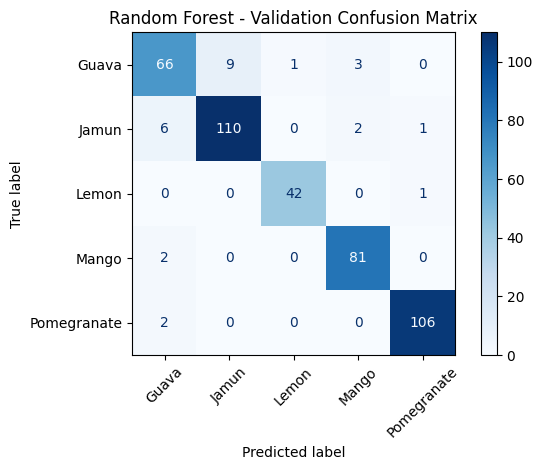

In [36]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Print classification report
print("CLASSIFICATION REPORT\n")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=rf_model.classes_,
        zero_division=0
    )
)

# Calculate confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=rf_model.classes_
)

print("Confusion matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 most important features:
       Feature  Importance
         H_std    0.086928
     Leaf_Area    0.073607
        S_mean    0.060641
         LBP_2    0.058899
        B_mean    0.052647
         LBP_7    0.049514
Leaf_Perimeter    0.047686
        R_mean    0.045633
  Aspect_Ratio    0.044903
        V_mean    0.041492


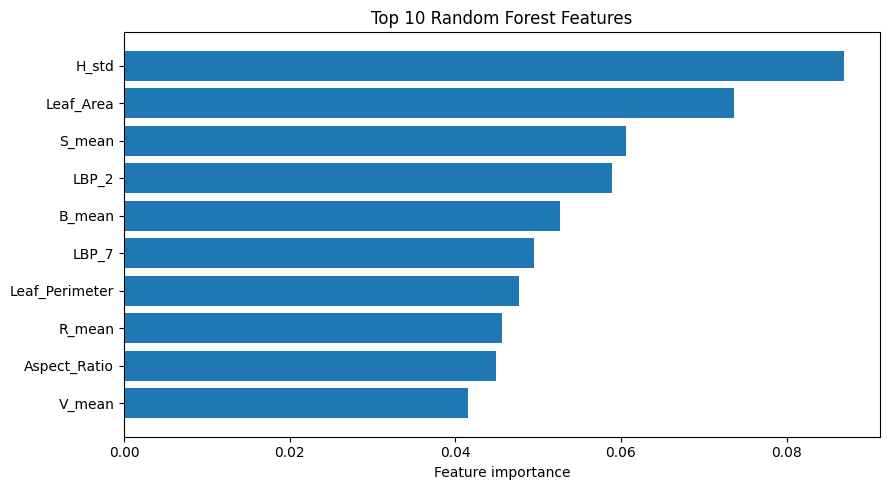

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 most important features:")
print(importance_df.head(10).to_string(index=False))

# Plot the top 10 features
top10 = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(top10["Feature"], top10["Importance"])
plt.xlabel("Feature importance")
plt.title("Top 10 Random Forest Features")
plt.tight_layout()
plt.show()

In [38]:
import os

base_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/images/train"

species_list = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

print("Checking filename order...\n")

for species in species_list:
    species_path = os.path.join(base_path, species)

    actual_files = sorted([
        f for f in os.listdir(species_path)
        if os.path.isfile(os.path.join(species_path, f))
    ])

    saved_files = texture_shape_df.loc[
        texture_shape_df["Species"] == species,
        "Filename"
    ].tolist()

    # Some files were skipped during feature extraction.
    saved_files_set = set(saved_files)
    actual_saved_order = [
        f for f in actual_files if f in saved_files_set
    ]

    print(f"{species}:")
    print("  Saved feature rows:", len(saved_files))
    print("  Unique saved filenames:", len(saved_files_set))
    print("  Matches sorted image order:", saved_files == actual_saved_order)

Checking filename order...

Mango:
  Saved feature rows: 412
  Unique saved filenames: 412
  Matches sorted image order: True
Guava:
  Saved feature rows: 397
  Unique saved filenames: 397
  Matches sorted image order: True
Jamun:
  Saved feature rows: 595
  Unique saved filenames: 595
  Matches sorted image order: True
Lemon:
  Saved feature rows: 216
  Unique saved filenames: 216
  Matches sorted image order: True
Pomegranate:
  Saved feature rows: 538
  Unique saved filenames: 538
  Matches sorted image order: True


In [39]:
import os

base_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/images/train"

species_list = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

print("Checking color-feature row counts...\n")

for species in species_list:
    species_path = os.path.join(base_path, species)

    actual_files = sorted([
        f for f in os.listdir(species_path)
        if os.path.isfile(os.path.join(species_path, f))
    ])

    saved_files = texture_shape_df.loc[
        texture_shape_df["Species"] == species,
        "Filename"
    ].tolist()

    color_count = (color_df["Species"] == species).sum()

    print(f"{species}:")
    print("  Images in folder:", len(actual_files))
    print("  Color feature rows:", color_count)
    print("  Texture/shape rows:", len(saved_files))
    print("  Counts match:", color_count == len(saved_files))

Checking color-feature row counts...

Mango:
  Images in folder: 414
  Color feature rows: 412
  Texture/shape rows: 412
  Counts match: True
Guava:
  Images in folder: 398
  Color feature rows: 397
  Texture/shape rows: 397
  Counts match: True
Jamun:
  Images in folder: 603
  Color feature rows: 595
  Texture/shape rows: 595
  Counts match: True
Lemon:
  Images in folder: 216
  Color feature rows: 216
  Texture/shape rows: 216
  Counts match: True
Pomegranate:
  Images in folder: 538
  Color feature rows: 538
  Texture/shape rows: 538
  Counts match: True


In [44]:
import os
import cv2
import pandas as pd

base_path = "/content/drive/MyDrive/Leaf_Classification/Dataset/images/train"
output_path = "/content/drive/MyDrive/Leaf_Classification/color_features_with_filenames.csv"

species_list = ["Mango", "Guava", "Jamun", "Lemon", "Pomegranate"]

all_color_features = []
failed_images = []

for species in species_list:
    species_path = os.path.join(base_path, species)

    image_files = sorted([
        f for f in os.listdir(species_path)
        if os.path.isfile(os.path.join(species_path, f))
    ])

    processed = 0

    for filename in image_files:
        image_path = os.path.join(species_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            failed_images.append((species, filename, "Unreadable image"))
            continue

        image = cv2.resize(image, (256, 256))
        mask = create_leaf_mask(image)

        if mask is None or cv2.countNonZero(mask) == 0:
            failed_images.append((species, filename, "Empty mask"))
            continue

        features = extract_color_features(image, mask)
        features["Filename"] = filename
        features["Species"] = species

        all_color_features.append(features)
        processed += 1

    print(f"{species}: processed {processed}/{len(image_files)} images")

color_named_df = pd.DataFrame(all_color_features)
color_named_df.to_csv(output_path, index=False)

print("\nFilename-linked color features saved!")
print("Shape:", color_named_df.shape)
print("Failed or skipped images:", len(failed_images))
print("Saved to:", output_path)

if failed_images:
    print("\nFirst skipped images:")
    print(failed_images[:10])

Mango: processed 412/414 images
Guava: processed 397/398 images
Jamun: processed 595/603 images
Lemon: processed 216/216 images
Pomegranate: processed 538/538 images

Filename-linked color features saved!
Shape: (2158, 14)
Failed or skipped images: 11
Saved to: /content/drive/MyDrive/Leaf_Classification/color_features_with_filenames.csv

First skipped images:
[('Mango', 'Mango_diseased_(P0b)_0012_0164.JPG', 'Empty mask'), ('Mango', 'Mango_diseased_(P0b)_0012_0239.JPG', 'Unreadable image'), ('Guava', 'Gauva_diseased_(P3b)_0015_0024.JPG', 'Empty mask'), ('Jamun', 'Jamun_diseased_(P5b)_0017_0163.JPG', 'Empty mask'), ('Jamun', 'Jamun_diseased_(P5b)_0017_0173.JPG', 'Empty mask'), ('Jamun', 'Jamun_diseased_(P5b)_0017_0180.JPG', 'Empty mask'), ('Jamun', 'Jamun_healthy_(P5a)_0005_0063.JPG', 'Empty mask'), ('Jamun', 'Jamun_healthy_(P5a)_0005_0064.JPG', 'Empty mask'), ('Jamun', 'Jamun_healthy_(P5a)_0005_0182.JPG', 'Empty mask'), ('Jamun', 'Jamun_healthy_(P5a)_0005_0246.JPG', 'Empty mask')]


In [45]:
import os
import pandas as pd

# Load the filename-linked colour features
folder = "/content/drive/MyDrive/Leaf_Classification"

color_named_df = pd.read_csv(
    os.path.join(folder, "color_features_with_filenames.csv")
)

# Reload texture and shape features
texture_shape_df = pd.read_csv(
    os.path.join(folder, "texture_shape_features.csv")
)

# Check for duplicate image identities
print("Duplicate colour entries:",
      color_named_df.duplicated(["Species", "Filename"]).sum())

print("Duplicate texture/shape entries:",
      texture_shape_df.duplicated(["Species", "Filename"]).sum())

# Find image identities present in both tables
color_keys = set(zip(color_named_df["Species"], color_named_df["Filename"]))
texture_keys = set(zip(texture_shape_df["Species"], texture_shape_df["Filename"]))

print("\nImages in colour table:", len(color_keys))
print("Images in texture/shape table:", len(texture_keys))
print("Matching images:", len(color_keys & texture_keys))
print("Only in colour table:", len(color_keys - texture_keys))
print("Only in texture/shape table:", len(texture_keys - color_keys))

# Merge features by actual image identity
combined_df = pd.merge(
    color_named_df,
    texture_shape_df,
    on=["Species", "Filename"],
    how="inner",
    validate="one_to_one",
    suffixes=("_color", "_texture_shape")
)

# Save the merged dataset
combined_path = os.path.join(folder, "combined_features.csv")
combined_df.to_csv(combined_path, index=False)

print("\nVerified combined dataset saved!")
print("Shape:", combined_df.shape)
print("Saved to:", combined_path)
print("\nImages per species:")
print(combined_df["Species"].value_counts().sort_index())

Duplicate colour entries: 0
Duplicate texture/shape entries: 0

Images in colour table: 2158
Images in texture/shape table: 2158
Matching images: 2158
Only in colour table: 0
Only in texture/shape table: 0

Verified combined dataset saved!
Shape: (2158, 36)
Saved to: /content/drive/MyDrive/Leaf_Classification/combined_features.csv

Images per species:
Species
Guava          397
Jamun          595
Lemon          216
Mango          412
Pomegranate    538
Name: count, dtype: int64


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Separate the numerical features from the target label
X = combined_df.drop(columns=["Species", "Filename"])
y = combined_df["Species"]

# Create a new training and validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Numerical features:", X_train.shape[1])

# Create a fresh Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train on the corrected feature data
rf_model.fit(X_train, y_train)

# Predict validation labels
y_val_pred = rf_model.predict(X_val)

# Calculate accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("\nCorrected model training completed!")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

Training images: 1726
Validation images: 432
Numerical features: 34

Corrected model training completed!
Validation accuracy: 93.75%


UPDATED CLASSIFICATION REPORT

              precision    recall  f1-score   support

       Guava       0.87      0.84      0.85        79
       Jamun       0.92      0.92      0.92       119
       Lemon       0.98      0.98      0.98        43
       Mango       0.94      0.98      0.96        83
 Pomegranate       0.98      0.98      0.98       108

    accuracy                           0.94       432
   macro avg       0.94      0.94      0.94       432
weighted avg       0.94      0.94      0.94       432

Updated confusion matrix:
[[ 66   9   1   3   0]
 [  6 110   0   2   1]
 [  0   0  42   0   1]
 [  2   0   0  81   0]
 [  2   0   0   0 106]]


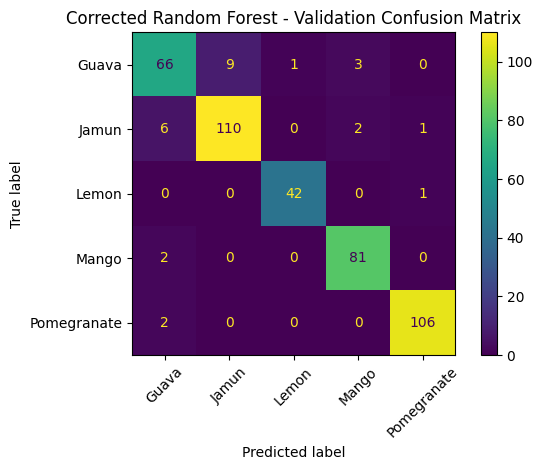

In [47]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt

# Print updated classification metrics
print("UPDATED CLASSIFICATION REPORT\n")

print(classification_report(
    y_val,
    y_val_pred,
    zero_division=0
))

# Create confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=rf_model.classes_
)

print("Updated confusion matrix:")
print(cm)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(values_format="d")
plt.title("Corrected Random Forest - Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 features in the corrected model:
       Feature  Importance
         H_std    0.086928
     Leaf_Area    0.073607
        S_mean    0.060641
         LBP_2    0.058899
        B_mean    0.052647
         LBP_7    0.049514
Leaf_Perimeter    0.047686
        R_mean    0.045633
  Aspect_Ratio    0.044903
        V_mean    0.041492


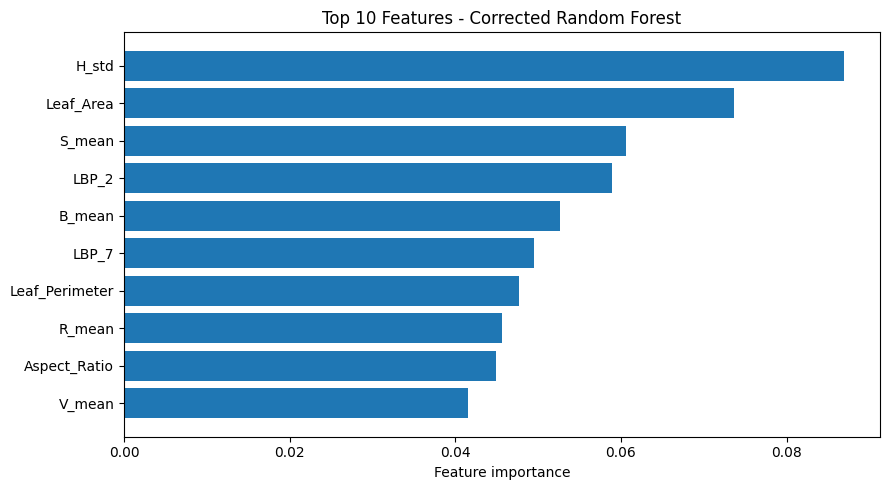

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the corrected model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 features
print("Top 10 features in the corrected model:")
print(importance_df.head(10).to_string(index=False))

# Plot the results
top10 = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(top10["Feature"], top10["Importance"])
plt.xlabel("Feature importance")
plt.title("Top 10 Features - Corrected Random Forest")
plt.tight_layout()
plt.show()

In [49]:
import os

base_path = "/content/drive/MyDrive/Leaf_Classification"
dataset_path = os.path.join(base_path, "Dataset", "images")

print("Test folder exists:", os.path.isdir(os.path.join(dataset_path, "test")))
print("Colour extraction function exists:", "extract_color_features" in globals())
print("Texture extraction function exists:", "extract_texture_features" in globals())
print("Shape extraction function exists:", "extract_shape_features" in globals())
print("Mask function exists:", "create_leaf_mask" in globals())
print("Combined training features exist:", os.path.isfile(os.path.join(base_path, "combined_features.csv")))

Test folder exists: True
Colour extraction function exists: True
Texture extraction function exists: True
Shape extraction function exists: True
Mask function exists: True
Combined training features exist: True


In [50]:
import os
import cv2
import pandas as pd
from tqdm.auto import tqdm

base_path = "/content/drive/MyDrive/Leaf_Classification"
test_path = os.path.join(base_path, "Dataset", "images", "test")

color_rows = []
texture_shape_rows = []

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for species in sorted(os.listdir(test_path)):
    species_path = os.path.join(test_path, species)

    if not os.path.isdir(species_path):
        continue

    files = sorted([
        f for f in os.listdir(species_path)
        if f.lower().endswith(valid_extensions)
    ])

    processed = 0

    for filename in tqdm(files, desc=species):
        image_path = os.path.join(species_path, filename)
        image = cv2.imread(image_path)

        if image is None:
            print(f"Unreadable image skipped: {image_path}")
            continue

        image = cv2.resize(image, (256, 256))
        mask = create_leaf_mask(image)

        if mask is None or mask.sum() == 0:
            print(f"Empty mask skipped: {image_path}")
            continue

        color_features = extract_color_features(image, mask)
        texture_features = extract_texture_features(image, mask)
        shape_features = extract_shape_features(mask)

        # Store colour features with image identity
        color_row = dict(color_features)
        color_row["Filename"] = filename
        color_row["Species"] = species
        color_rows.append(color_row)

        # Store texture and shape features with image identity
        combined_row = {}
        combined_row.update(texture_features)
        combined_row.update(shape_features)
        combined_row["Filename"] = filename
        combined_row["Species"] = species
        texture_shape_rows.append(combined_row)

        processed += 1

    print(f"{species}: processed {processed}/{len(files)} images")

test_color_df = pd.DataFrame(color_rows)
test_texture_shape_df = pd.DataFrame(texture_shape_rows)

test_color_df.to_csv(
    os.path.join(base_path, "test_color_features.csv"),
    index=False
)

test_texture_shape_df.to_csv(
    os.path.join(base_path, "test_texture_shape_features.csv"),
    index=False
)

print("\nTest feature extraction completed.")
print("Colour feature table:", test_color_df.shape)
print("Texture/shape feature table:", test_texture_shape_df.shape)
print("Files saved in:", base_path)

Guava:   0%|          | 0/10 [00:00<?, ?it/s]

Guava: processed 10/10 images


Jamun:   0%|          | 0/10 [00:00<?, ?it/s]

Jamun: processed 10/10 images


Lemon:   0%|          | 0/10 [00:00<?, ?it/s]

Lemon: processed 10/10 images


Mango:   0%|          | 0/10 [00:00<?, ?it/s]

Mango: processed 10/10 images


Pomegranate:   0%|          | 0/10 [00:00<?, ?it/s]

Pomegranate: processed 10/10 images

Test feature extraction completed.
Colour feature table: (50, 14)
Texture/shape feature table: (50, 24)
Files saved in: /content/drive/MyDrive/Leaf_Classification


In [51]:
import os
import pandas as pd

base_path = "/content/drive/MyDrive/Leaf_Classification"

# Load the two saved test feature tables
test_color_df = pd.read_csv(
    os.path.join(base_path, "test_color_features.csv")
)

test_texture_shape_df = pd.read_csv(
    os.path.join(base_path, "test_texture_shape_features.csv")
)

# Check that each image appears only once in each table
print(
    "Duplicate colour image records:",
    test_color_df.duplicated(["Species", "Filename"]).sum()
)

print(
    "Duplicate texture/shape image records:",
    test_texture_shape_df.duplicated(["Species", "Filename"]).sum()
)

# Merge features belonging to the same image
test_combined_df = pd.merge(
    test_color_df,
    test_texture_shape_df,
    on=["Species", "Filename"],
    how="inner",
    validate="one_to_one",
    suffixes=("_color", "_texture")
)

# Save the combined test features
test_combined_df.to_csv(
    os.path.join(base_path, "test_combined_features.csv"),
    index=False
)

print("\nCombined test feature table:", test_combined_df.shape)
print("\nImages per species:")
print(test_combined_df["Species"].value_counts().sort_index())

print("\nCombined test features saved successfully.")

Duplicate colour image records: 0
Duplicate texture/shape image records: 0

Combined test feature table: (50, 36)

Images per species:
Species
Guava          10
Jamun          10
Lemon          10
Mango          10
Pomegranate    10
Name: count, dtype: int64

Combined test features saved successfully.


In [52]:
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# 1. Select the 34 numerical features in the same order as training
feature_columns = X_train.columns.tolist()

X_test = test_combined_df[feature_columns]
y_test = test_combined_df["Species"]

# 2. Verify that test features match the model's training features
print("Number of model features:", len(feature_columns))
print("Number of test features:", X_test.shape[1])
print("Feature columns match:", list(X_test.columns) == feature_columns)

# 3. Predict species using the already-trained model
y_test_pred = rf_model.predict(X_test)

# 4. Compare predictions with the actual labels
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"\nFinal test accuracy: {test_accuracy * 100:.2f}%")
print(f"Correct predictions: {(y_test == y_test_pred).sum()} out of {len(y_test)}")

print("\nTest classification report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

# 5. Display each image's actual and predicted species
results_df = test_combined_df[["Filename", "Species"]].copy()
results_df["Predicted_Species"] = y_test_pred
results_df["Correct"] = results_df["Species"] == results_df["Predicted_Species"]

print("\nIndividual test predictions:")
print(results_df.to_string(index=False))

Number of model features: 34
Number of test features: 34
Feature columns match: True

Final test accuracy: 90.00%
Correct predictions: 45 out of 50

Test classification report:
              precision    recall  f1-score   support

       Guava       0.88      0.70      0.78        10
       Jamun       0.75      0.90      0.82        10
       Lemon       1.00      0.90      0.95        10
       Mango       1.00      1.00      1.00        10
 Pomegranate       0.91      1.00      0.95        10

    accuracy                           0.90        50
   macro avg       0.91      0.90      0.90        50
weighted avg       0.91      0.90      0.90        50


Individual test predictions:
                                Filename     Species Predicted_Species  Correct
      Gauva_diseased_(P3b)_0015_0001.JPG       Guava             Jamun    False
      Gauva_diseased_(P3b)_0015_0002.JPG       Guava             Guava     True
      Gauva_diseased_(P3b)_0015_0003.JPG       Guava            

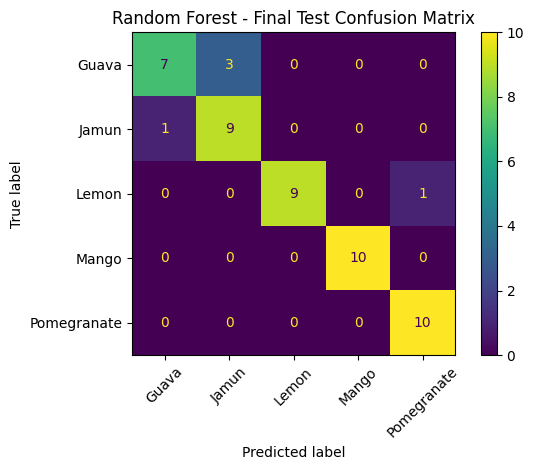

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare actual species with predicted species
cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=rf_model.classes_
)

# Draw the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=rf_model.classes_
)

disp.plot(values_format="d")
plt.title("Random Forest - Final Test Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
import os
import joblib

# Folder where we will save the model
base_path = "/content/drive/MyDrive/Leaf_Classification"

# Save the trained Random Forest model
model_path = os.path.join(base_path, "leaf_random_forest.pkl")
joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: /content/drive/MyDrive/Leaf_Classification/leaf_random_forest.pkl


In [55]:
import os

base_path = "/content/drive/MyDrive/Leaf_Classification"

# Save the predictions and actual labels as a CSV file
results_path = os.path.join(base_path, "final_test_predictions.csv")

results_df.to_csv(results_path, index=False)

print("Test predictions saved successfully!")
print("Total test images:", len(results_df))
print("Correct predictions:", results_df["Correct"].sum())
print("Incorrect predictions:", (~results_df["Correct"]).sum())
print("Saved at:", results_path)

Test predictions saved successfully!
Total test images: 50
Correct predictions: 45
Incorrect predictions: 5
Saved at: /content/drive/MyDrive/Leaf_Classification/final_test_predictions.csv


In [56]:
import os
import json

base_path = "/content/drive/MyDrive/Leaf_Classification"

feature_path = os.path.join(base_path, "model_feature_names.json")

with open(feature_path, "w") as file:
    json.dump(X_train.columns.tolist(), file, indent=4)

print("Feature names saved successfully!")
print("Number of features:", len(X_train.columns))
print("Saved at:", feature_path)

Feature names saved successfully!
Number of features: 34
Saved at: /content/drive/MyDrive/Leaf_Classification/model_feature_names.json


In [57]:
import os
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

base_path = "/content/drive/MyDrive/Leaf_Classification"

# Create a report for each species
report = classification_report(
    y_test,
    y_test_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_path = os.path.join(base_path, "final_test_classification_report.csv")
report_df.to_csv(report_path, index=True)

# Save the confusion matrix
cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=rf_model.classes_
)

cm_df = pd.DataFrame(
    cm_test,
    index=rf_model.classes_,
    columns=rf_model.classes_
)

cm_path = os.path.join(base_path, "final_test_confusion_matrix.csv")
cm_df.to_csv(cm_path, index=True)

print("Final evaluation reports saved successfully!")
print("Classification report:", report_path)
print("Confusion matrix:", cm_path)

Final evaluation reports saved successfully!
Classification report: /content/drive/MyDrive/Leaf_Classification/final_test_classification_report.csv
Confusion matrix: /content/drive/MyDrive/Leaf_Classification/final_test_confusion_matrix.csv


In [58]:
import os

base_path = "/content/drive/MyDrive/Leaf_Classification"

print("PROJECT FILES\n")

for filename in sorted(os.listdir(base_path)):
    filepath = os.path.join(base_path, filename)

    if os.path.isfile(filepath):
        print(filename)

PROJECT FILES

color_features.csv
color_features_with_filenames.csv
combined_features.csv
final_test_classification_report.csv
final_test_confusion_matrix.csv
final_test_predictions.csv
leaf_random_forest.pkl
model_feature_names.json
test_color_features.csv
test_combined_features.csv
test_texture_shape_features.csv
texture_shape_features.csv
